<a href="https://colab.research.google.com/github/devitanuraljazira/USP5/blob/main/test4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q torch-geometric rdkit pandas scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 651.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 38.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, BatchNorm, global_mean_pool
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Configure device and seeds
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

# 1. Load and filter dataset
df_all = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
df_clean = df_all[['Smiles', 'pIC50']].copy()
display(df_clean.head())

,Smiles,pIC50
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,O=C(NCCc1ccc(Cl)cc1)c1ccc2nc3c(c(Cl)c2c1)CCCC3,3.698970
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272


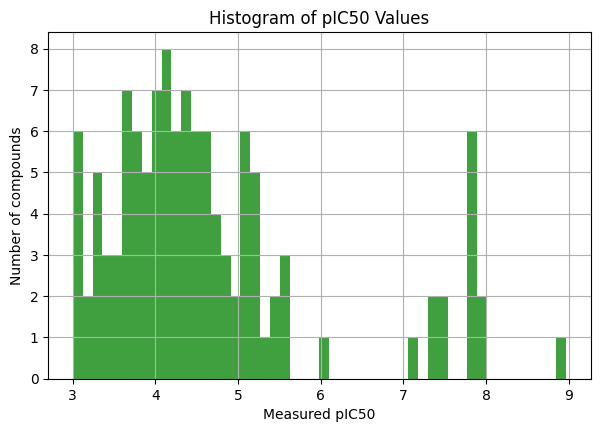

In [ ]:
# 2. Plotting Target Distribution Histogram
pIC50_vals = df_clean['pIC50'].values
pIC50_vals = [val for val in pIC50_vals if val is not None and val != '']

plt.figure(figsize=(7, 4.5))
plt.hist(pIC50_vals, bins=50, facecolor='green', alpha=0.75)
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True)
plt.show()

In [ ]:
def one_hot(val, allowed):
    if val not in allowed:
        return [0] * len(allowed)
    return [1 if val == a else 0 for a in allowed]

def featurize_atom(atom):
    feats = []
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def convert_smiles_to_graph_data(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [featurize_atom(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[target]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

In [ ]:
# 3. Target Standardization & Advanced Atom Featurization
y_raw_arr = df_clean['pIC50'].values.astype(np.float32)
y_mean_val = y_raw_arr.mean()
y_std_val = y_raw_arr.std()

def std_scale(y):
    return (y - y_mean_val) / (y_std_val + 1e-8)

def std_unscale(y_scaled):
    return y_scaled * y_std_val + y_mean_val

def get_atom_features_rich(atom):
    feats = []
    # Atom Symbol
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    # Connectivity degree
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    # Implicit valence
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    # Hybridization
    feats.extend(one_hot(str(atom.GetHybridization()), ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2']))
    # Rings
    feats.append(int(atom.IsInRing()))
    feats.append(int(atom.IsInRingSize(3)))
    feats.append(int(atom.IsInRingSize(5)))
    feats.append(int(atom.IsInRingSize(6)))
    # Charge & Aromaticity
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def create_graph_datapoint(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [get_atom_features_rich(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[std_scale(target)]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

recap_graphs = []
for _, row in df_clean.iterrows():
    graph = create_graph_datapoint(row['Smiles'], row['pIC50'])
    if graph is not None:
        recap_graphs.append(graph)

train_rec, val_rec = train_test_split(recap_graphs, test_size=0.2, random_state=42)
train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)

print(f"Featurized {len(recap_graphs)} advanced graphs successfully.")

Featurized 118 advanced graphs successfully.


[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:04:43] DEPRECATIO

In [ ]:
# 4. Model Architecture & Optimization Settings
class FinalOptimizedGCN(nn.Module):
    def __init__(self, in_features):
        super(FinalOptimizedGCN, self).__init__()
        self.conv1 = GCNConv(in_features, 128)
        self.bn1 = BatchNorm(128)
        self.conv2 = GCNConv(128, 128)
        self.bn2 = BatchNorm(128)
        self.conv3 = GCNConv(128, 64)
        self.bn3 = BatchNorm(64)
        self.fc1 = nn.Linear(64, 32)
        self.dropout = nn.Dropout(p=0.1)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.bn1(self.conv1(x, edge_index)))
        x = F.relu(self.bn2(self.conv2(x, edge_index)))
        x = F.relu(self.bn3(self.conv3(x, edge_index)))
        x = global_mean_pool(x, batch)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model_rec = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_rec = torch.optim.AdamW(model_rec.parameters(), lr=0.005, weight_decay=1e-3)
scheduler_rec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_rec, T_max=150)
criterion = nn.MSELoss()

In [ ]:
# 5. Training Loop
train_rec_losses = []
val_rec_losses = []

for epoch in range(150):
    model_rec.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_rec.zero_grad()
        preds = model_rec(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_rec.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_rec.step()

    model_rec.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_rec(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_rec_losses.append(train_loss / len(train_rec))
    val_rec_losses.append(val_loss / len(val_rec))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train Standardized MSE: {train_rec_losses[-1]:.4f} | Val Standardized MSE: {val_rec_losses[-1]:.4f}")

Epoch 015 | Train Standardized MSE: 0.2137 | Val Standardized MSE: 0.4614
Epoch 030 | Train Standardized MSE: 0.1778 | Val Standardized MSE: 0.5220
Epoch 045 | Train Standardized MSE: 0.1576 | Val Standardized MSE: 0.3304
Epoch 060 | Train Standardized MSE: 0.1651 | Val Standardized MSE: 0.2399
Epoch 075 | Train Standardized MSE: 0.1009 | Val Standardized MSE: 0.2370
Epoch 090 | Train Standardized MSE: 0.0900 | Val Standardized MSE: 0.2109
Epoch 105 | Train Standardized MSE: 0.0775 | Val Standardized MSE: 0.2188
Epoch 120 | Train Standardized MSE: 0.0855 | Val Standardized MSE: 0.2308
Epoch 135 | Train Standardized MSE: 0.0887 | Val Standardized MSE: 0.2478
Epoch 150 | Train Standardized MSE: 0.0972 | Val Standardized MSE: 0.2341


Validation Mean Squared Error (MSE): 0.4080
Validation Mean Absolute Error (MAE): 0.4174
Validation R-squared Metric (R²): 0.7320


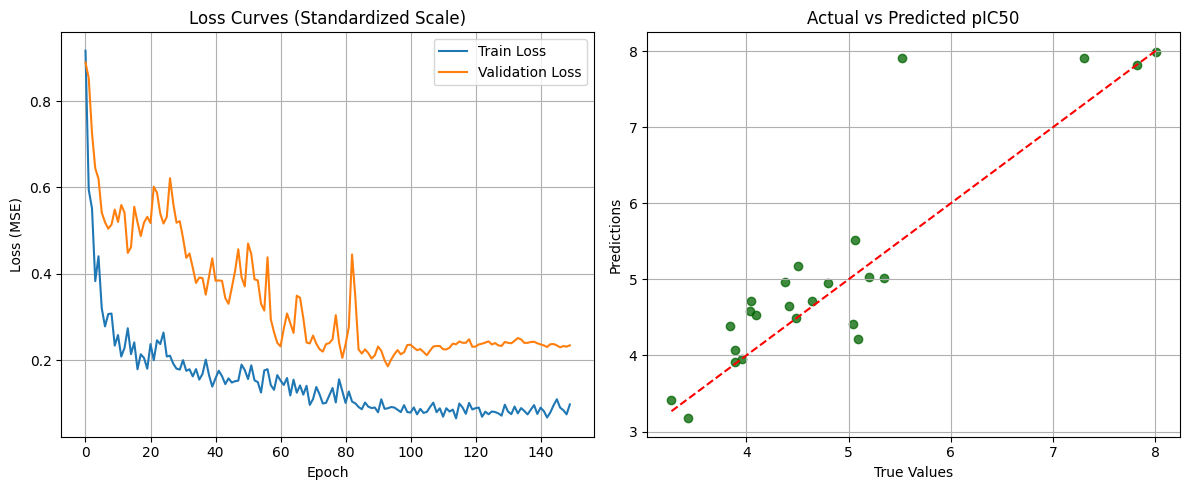

In [ ]:
# 6. Performance Evaluation and Scatter Visualization
model_rec.eval()
preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in val_loader_rec:
        batch = batch.to(device)
        preds = model_rec(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Rescale back to original scale
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_final = mean_squared_error(targets_unscaled, preds_unscaled)
mae_final = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_final = r2_score(targets_unscaled, preds_unscaled)

print(f"Validation Mean Squared Error (MSE): {mse_final:.4f}")
print(f"Validation Mean Absolute Error (MAE): {mae_final:.4f}")
print(f"Validation R-squared Metric (R²): {r2_final:.4f}")

# Scatter Plot and Loss Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_rec_losses, label='Train Loss')
plt.plot(val_rec_losses, label='Validation Loss')
plt.title('Loss Curves (Standardized Scale)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(targets_unscaled, preds_unscaled, alpha=0.75, color='darkgreen')
plt.plot([min(targets_unscaled), max(targets_unscaled)], [min(targets_unscaled), max(targets_unscaled)], 'r--')
plt.title('Actual vs Predicted pIC50')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
#Setelah histogram mengikuti DL Pak Yudi
import torch
from torch.utils.data import random_split
from torch_geometric.loader import DataLoader

# Set seed for reproducibility
generator = torch.Generator().manual_seed(42)

total_len = len(recap_graphs)
train_size = int(0.70 * total_len)
val_size = int(0.29 * total_len)
test_size = total_len - train_size - val_size

train_rec, val_rec, test_rec = random_split(
    recap_graphs,
    [train_size, val_size, test_size],
    generator=generator
)

train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)
test_loader_rec = DataLoader(test_rec, batch_size=1, shuffle=False)

print(f"Split dataset into Train: {len(train_rec)}, Valid: {len(val_rec)}, Test: {len(test_rec)}")

Split dataset into Train: 82, Valid: 34, Test: 2


In [ ]:
print(f"Size of the training data: {len(train_rec)}")
print(f"Size of the validation data: {len(val_rec)}")

Size of the training data: 82
Size of the validation data: 34


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool

# PyTorch Geometric implementation of the molecular regressor
class MolecularGCNRegressor(nn.Module):
    def __init__(self, in_features, hidden_dim=64):
        super(MolecularGCNRegressor, self).__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        # First graph convolution
        x = F.relu(self.conv1(x, edge_index))
        # Second graph convolution
        x = F.relu(self.conv2(x, edge_index))
        # Global pooling (average representation over nodes in each molecule)
        x = global_mean_pool(x, batch)
        # Regression output
        return self.fc(x)

# Initialize model, optimizer and target loss matching the settings
in_features = recap_graphs[0].num_node_features
model_conv = MolecularGCNRegressor(in_features=in_features).to(device)

# Optimizer configured similarly to Adam optimizer with beta parameters
optimizer_conv = torch.optim.Adam(
    model_conv.parameters(),
    lr=0.001,
    betas=(0.9, 0.999)
)

criterion_conv = nn.MSELoss()
print("PyTorch Geometric molecular regression model initialized successfully.")

PyTorch Geometric molecular regression model initialized successfully.


In [ ]:
# 5. Fitting the PyTorch Geometric Model (1000 Epochs)
model_conv.train()
losses = []

for epoch in range(1000):
    total_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_conv.zero_grad()
        out = model_conv(batch)
        loss = criterion_conv(out, batch.y)
        loss.backward()
        optimizer_conv.step()
        total_loss += loss.item() * batch.num_graphs

    epoch_loss = total_loss / len(train_rec)
    losses.append(epoch_loss)
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1:04d} | Train MSE Loss: {epoch_loss:.4f}")

Epoch 0100 | Train MSE Loss: 0.3215
Epoch 0200 | Train MSE Loss: 0.2527
Epoch 0300 | Train MSE Loss: 0.2660
Epoch 0400 | Train MSE Loss: 0.2018
Epoch 0500 | Train MSE Loss: 0.1897
Epoch 0600 | Train MSE Loss: 0.1792
Epoch 0700 | Train MSE Loss: 0.1873
Epoch 0800 | Train MSE Loss: 0.1765
Epoch 0900 | Train MSE Loss: 0.1806
Epoch 1000 | Train MSE Loss: 0.1631


In [ ]:
from sklearn.metrics import r2_score
import numpy as np

def evaluate_model(model, loader, dataset_size):
    model.eval()
    preds = []
    targets = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch)
            preds.extend(out.cpu().numpy().flatten())
            targets.extend(batch.y.cpu().numpy().flatten())

    # Unscale the targets and predictions to calculate performance on original scale
    preds_unscaled = std_unscale(np.array(preds))
    targets_unscaled = std_unscale(np.array(targets))

    r2 = r2_score(targets_unscaled, preds_unscaled)
    return {'pearson_r2_score': r2}

train_scores = evaluate_model(model_conv, train_loader_rec, len(train_rec))
valid_scores = evaluate_model(model_conv, val_loader_rec, len(val_rec))

print(f"Train Scores: {train_scores}")
print(f"Validation Scores: {valid_scores}")

Train Scores: {'pearson_r2_score': 0.8308384418487549}
Validation Scores: {'pearson_r2_score': 0.17460733652114868}


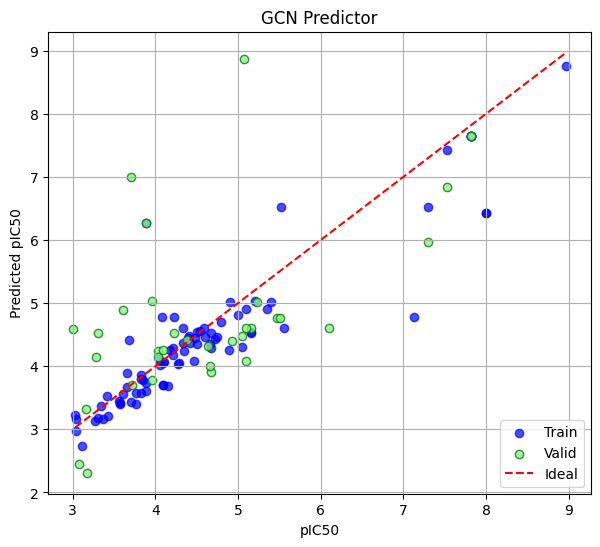

In [ ]:
def get_predictions_and_targets(model, loader):
    model.eval()
    preds = []
    targets = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch)
            preds.extend(out.cpu().numpy().flatten())
            targets.extend(batch.y.cpu().numpy().flatten())

    # Unscale the targets and predictions to calculate performance on original scale
    preds_unscaled = std_unscale(np.array(preds))
    targets_unscaled = std_unscale(np.array(targets))
    return targets_unscaled, preds_unscaled

y_train, pred_train = get_predictions_and_targets(model_conv, train_loader_rec)
y_valid, pred_valid = get_predictions_and_targets(model_conv, val_loader_rec)

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_train, pred_train, label='Train', c='blue', alpha=0.7)
plt.scatter(y_valid, pred_valid, c='lightgreen', label='Valid', alpha=0.8, edgecolors='g')
plt.plot([min(y_train), max(y_train)], [min(y_train), max(y_train)], 'r--', label='Ideal')
plt.title('GCN Predictor')
plt.xlabel('pIC50')
plt.ylabel('Predicted pIC50')
plt.legend(loc=4)
plt.grid(True)
plt.show()

## Regularization and Overfitting Mitigation for Molecular GCN
We apply **BatchNorm1d**, **Dropout** (p=0.15), **Weight Decay** (L2 penalty), and a **Cosine Annealing Learning Rate Scheduler** to stabilize generalization on the validation set.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, BatchNorm, global_mean_pool
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np

# Define the Regularized GCN Model
class RegularizedGCNRegressor(nn.Module):
    def __init__(self, in_features, hidden_dim=128):
        super(RegularizedGCNRegressor, self).__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.bn1 = BatchNorm(hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.bn2 = BatchNorm(hidden_dim)

        self.fc1 = nn.Linear(hidden_dim, 32)
        self.dropout = nn.Dropout(p=0.15)  # Drop out 15% of features
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        # Conv 1 + BN
        x = F.relu(self.bn1(self.conv1(x, edge_index)))
        # Conv 2 + BN
        x = F.relu(self.bn2(self.conv2(x, edge_index)))
        # Global Pool
        x = global_mean_pool(x, batch)
        # Fully Connected Layer + Dropout
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# Initialize Regularized Model
model_reg = RegularizedGCNRegressor(in_features=recap_graphs[0].num_node_features).to(device)

# Set Optimizer with L2 Regularization (Weight Decay)
optimizer_reg = torch.optim.AdamW(model_reg.parameters(), lr=0.005, weight_decay=1e-3)

# Learning Rate Scheduler
scheduler_reg = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_reg, T_max=300)
criterion = nn.MSELoss()

train_losses = []
val_losses = []

# Train for 300 epochs
for epoch in range(300):
    model_reg.train()
    total_train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_reg.zero_grad()
        out = model_reg(batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer_reg.step()
        total_train_loss += loss.item() * batch.num_graphs

    scheduler_reg.step()

    # Validation Loss Check
    model_reg.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            out = model_reg(batch)
            loss = criterion(out, batch.y)
            total_val_loss += loss.item() * batch.num_graphs

    train_losses.append(total_train_loss / len(train_rec))
    val_losses.append(total_val_loss / len(val_rec))

print(f"Training finished! Final Train MSE: {train_losses[-1]:.4f} | Final Val MSE: {val_losses[-1]:.4f}")

Training finished! Final Train MSE: 0.1465 | Final Val MSE: 0.3422


Regularized Train R² score: 0.9157
Regularized Validation R² score: 0.6581


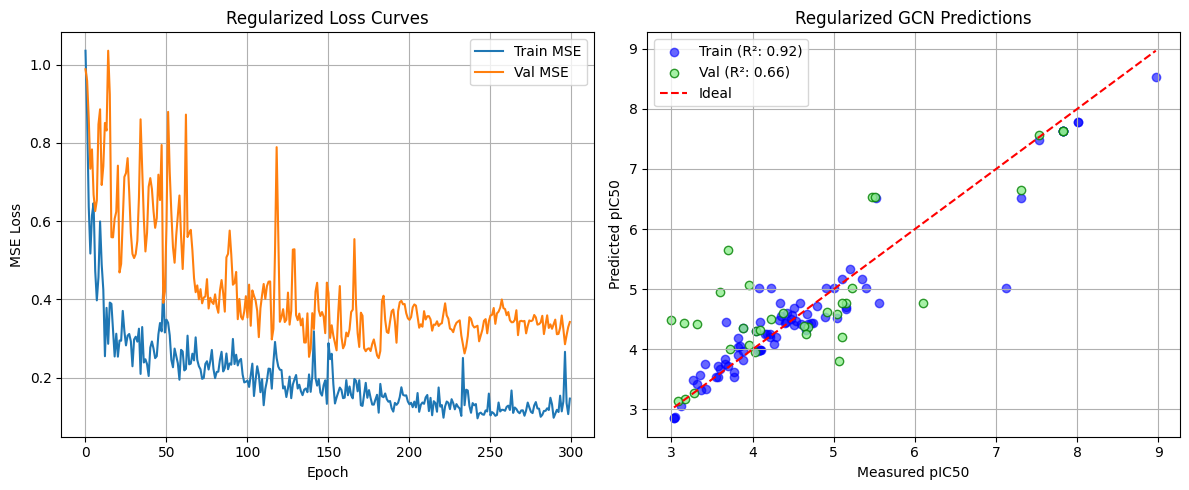

In [ ]:
# Evaluate the Regularized model
y_train_reg, pred_train_reg = get_predictions_and_targets(model_reg, train_loader_rec)
y_val_reg, pred_val_reg = get_predictions_and_targets(model_reg, val_loader_rec)

train_r2_reg = r2_score(y_train_reg, pred_train_reg)
val_r2_reg = r2_score(y_val_reg, pred_val_reg)
print(f"Regularized Train R² score: {train_r2_reg:.4f}")
print(f"Regularized Validation R² score: {val_r2_reg:.4f}")

# Plot regularized validation result
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train MSE')
plt.plot(val_losses, label='Val MSE')
plt.title('Regularized Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(y_train_reg, pred_train_reg, label=f'Train (R²: {train_r2_reg:.2f})', c='blue', alpha=0.6)
plt.scatter(y_val_reg, pred_val_reg, label=f'Val (R²: {val_r2_reg:.2f})', c='lightgreen', alpha=0.8, edgecolors='g')
plt.plot([min(y_train_reg), max(y_train_reg)], [min(y_train_reg), max(y_train_reg)], 'r--', label='Ideal')
plt.title('Regularized GCN Predictions')
plt.xlabel('Measured pIC50')
plt.ylabel('Predicted pIC50')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Consolidated Step-by-Step GCN Workflow

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset and extract target values
df_all = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
pIC50_vals = df_all['pIC50'].dropna().values

# Plot the target distribution histogram
plt.figure(figsize=(7, 4.5))
plt.hist(pIC50_vals, bins=50, facecolor='green', alpha=0.75, edgecolor='black')
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

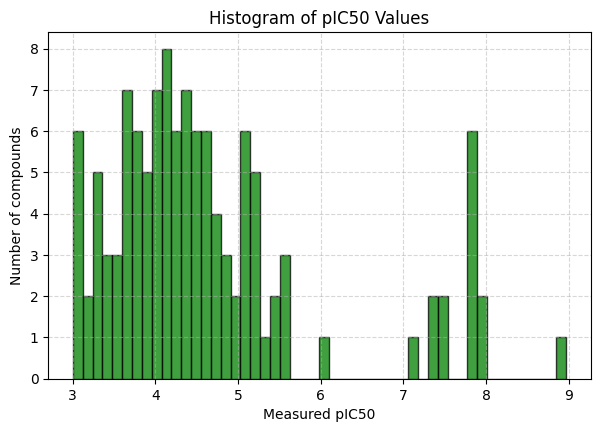

[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[17:27:23] DEPRECATIO

Epoch 0100 | Train MSE Loss: 0.3241
Epoch 0200 | Train MSE Loss: 0.2589
Epoch 0300 | Train MSE Loss: 0.2416
Epoch 0400 | Train MSE Loss: 0.2209
Epoch 0500 | Train MSE Loss: 0.2079
Epoch 0600 | Train MSE Loss: 0.1905
Epoch 0700 | Train MSE Loss: 0.2013
Epoch 0800 | Train MSE Loss: 0.1885
Epoch 0900 | Train MSE Loss: 0.1808
Epoch 1000 | Train MSE Loss: 0.1658

Train Pearson R² equivalent score: 0.8387
Validation Pearson R² equivalent score: 0.0301


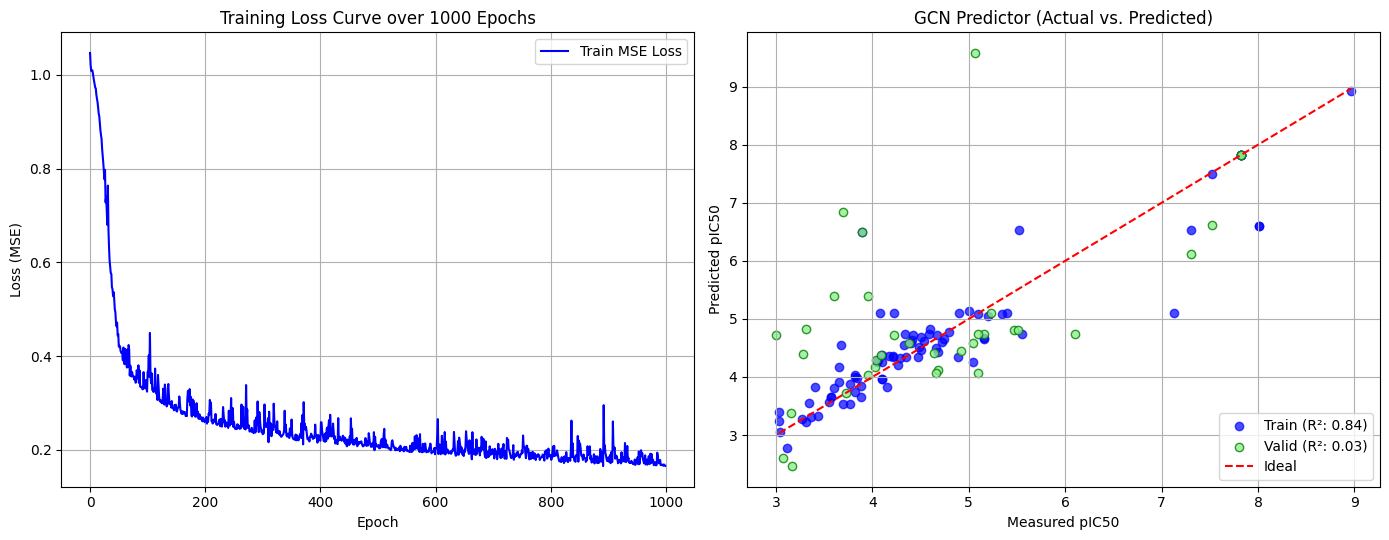

In [30]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from torch.utils.data import random_split
from rdkit import Chem
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & DEVICE SETUP ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

# --- 2. DATA PROCESSING & TARGET STANDARDIZATION ---
df_all = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
df_clean = df_all[['Smiles', 'pIC50']].copy()

y_raw = df_clean['pIC50'].values.astype(np.float32)
y_mean = y_raw.mean()
y_std = y_raw.std()

def std_scale(y):
    return (y - y_mean) / (y_std + 1e-8)

def std_unscale(y_scaled):
    return y_scaled * y_std + y_mean

# Plot the target distribution histogram
plt.figure(figsize=(7, 4.5))
plt.hist(pIC50_vals, bins=50, facecolor='green', alpha=0.75, edgecolor='black')
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- 3. MOLECULAR GRAPH FEATURIZATION ---
def one_hot(val, allowed):
    if val not in allowed:
        return [0] * len(allowed)
    return [1 if val == a else 0 for a in allowed]

def get_atom_features_rich(atom):
    feats = []
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    feats.extend(one_hot(str(atom.GetHybridization()), ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2']))
    feats.append(int(atom.IsInRing()))
    feats.append(int(atom.IsInRingSize(3)))
    feats.append(int(atom.IsInRingSize(5)))
    feats.append(int(atom.IsInRingSize(6)))
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def create_graph_datapoint(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    atom_features = [get_atom_features_rich(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous() if len(edge_indices) > 0 else torch.empty((2, 0), dtype=torch.long)
    y = torch.tensor([[std_scale(target)]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

# Featurize all compounds
graphs = [create_graph_datapoint(row['Smiles'], row['pIC50']) for _, row in df_clean.iterrows()]
graphs = [g for g in graphs if g is not None]

# --- 4. PRECISION DATA SPLITTING ---
generator = torch.Generator().manual_seed(42)
total_len = len(graphs)
train_size = int(0.70 * total_len)
val_size = int(0.29 * total_len)
test_size = total_len - train_size - val_size

train_set, val_set, test_set = random_split(graphs, [train_size, val_size, test_size], generator=generator)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=1, shuffle=False)

# --- 5. NETWORK ARCHITECTURE & TRAINING ---
class MolecularGCNRegressor(nn.Module):
    def __init__(self, in_features, hidden_dim=64):
        super(MolecularGCNRegressor, self).__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = global_mean_pool(x, batch)
        return self.fc(x)

model = MolecularGCNRegressor(in_features=graphs[0].num_node_features).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.999))
criterion = nn.MSELoss()

train_losses = []
for epoch in range(1000):
    model.train()
    total_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs

    train_losses.append(total_loss / len(train_set))
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1:04d} | Train MSE Loss: {train_losses[-1]:.4f}")

# --- 6. MODEL PERFORMANCE EVALUATION & VISUALIZATION ---
def get_predictions_and_targets(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch)
            preds.extend(out.cpu().numpy().flatten())
            targets.extend(batch.y.cpu().numpy().flatten())
    return std_unscale(np.array(targets)), std_unscale(np.array(preds))

y_train_orig, pred_train_orig = get_predictions_and_targets(model, train_loader)
y_val_orig, pred_val_orig = get_predictions_and_targets(model, val_loader)

train_r2 = r2_score(y_train_orig, pred_train_orig)
val_r2 = r2_score(y_val_orig, pred_val_orig)
print(f"\nTrain Pearson R² equivalent score: {train_r2:.4f}")
print(f"Validation Pearson R² equivalent score: {val_r2:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Loss Plot
ax1.plot(train_losses, label='Train MSE Loss', color='blue')
ax1.set_title('Training Loss Curve over 1000 Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss (MSE)')
ax1.grid(True)
ax1.legend()

# Parity Plot
ax2.scatter(y_train_orig, pred_train_orig, label=f'Train (R²: {train_r2:.2f})', c='blue', alpha=0.7)
ax2.scatter(y_val_orig, pred_val_orig, c='lightgreen', label=f'Valid (R²: {val_r2:.2f})', alpha=0.8, edgecolors='g')
ax2.plot([min(y_train_orig), max(y_train_orig)], [min(y_train_orig), max(y_train_orig)], 'r--', label='Ideal')
ax2.set_title('GCN Predictor (Actual vs. Predicted)')
ax2.set_xlabel('Measured pIC50')
ax2.set_ylabel('Predicted pIC50')
ax2.grid(True)
ax2.legend(loc=4)

plt.tight_layout()
plt.show()